In [1]:
import pandas as pd
import numpy as np

In [2]:
column_names = [
    'class_code', 'largest_spot_size', 'spot_dist', 'activity', 
    'evolution', 'prev_24h_activity', 'hist_complex', 
    'region_became_hist_complex', 'area', 'area_largest_spot', 
    'c_class_flares', 'm_class_flares', 'x_class_flares'
]

ds = pd.read_csv('flare.data2', sep='\s+', header=None, names=column_names, skiprows=1)

print(ds.head())

  class_code largest_spot_size spot_dist  activity  evolution  \
0          H                 A         X         1          3   
1          D                 R         O         1          3   
2          C                 S         O         1          3   
3          H                 R         X         1          2   
4          H                 S         X         1          1   

   prev_24h_activity  hist_complex  region_became_hist_complex  area  \
0                  1             1                           1     1   
1                  1             1                           2     1   
2                  1             1                           2     1   
3                  1             1                           1     1   
4                  1             1                           2     1   

   area_largest_spot  c_class_flares  m_class_flares  x_class_flares  
0                  1               0               0               0  
1                  1              

In [3]:
def prepare_flare_data(ds, target_letter):
    target_letter = target_letter.lower()
    target_col = f"{target_letter}_class_flares"
    all_targets = ['c_class_flares', 'm_class_flares', 'x_class_flares']
    X = ds.drop(columns=all_targets)
    y = ds[target_col].values
    return X, y

X, y = prepare_flare_data(ds, target_letter='c')

X = pd.get_dummies(X, drop_first=True)
print(X)

      activity  evolution  prev_24h_activity  hist_complex  \
0            1          3                  1             1   
1            1          3                  1             1   
2            1          3                  1             1   
3            1          2                  1             1   
4            1          1                  1             1   
...        ...        ...                ...           ...   
1061         1          2                  1             1   
1062         2          2                  1             1   
1063         1          2                  1             2   
1064         1          2                  1             1   
1065         1          1                  1             1   

      region_became_hist_complex  area  area_largest_spot  class_code_C  \
0                              1     1                  1         False   
1                              2     1                  1         False   
2                             

In [4]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)

In [5]:
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()
X_train_scaled = sc.fit_transform(X_train)
X_test_scaled = sc.transform(X_test)

In [19]:
from sklearn.linear_model import LassoCV

# Finds the best alpha parameter using 5-fold cross-validation
lasso_cv = LassoCV(cv=5, random_state=0)
lasso_cv.fit(X_train_scaled, y_train)

print(f"Optimal Alpha: {lasso_cv.alpha_}")

Optimal Alpha: 0.03077107116877399


In [20]:
# --------------------------- Lasso Regression ---------------------------
from sklearn.linear_model import Lasso
lasso = Lasso(alpha= 0.03077107116877399)
lasso.fit(X_train_scaled, y_train)

y_pred = lasso.predict(X_test_scaled)

In [21]:
from sklearn.metrics import mean_squared_error, r2_score

mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Mean Squared Error: {mse:.2f}")
print(f"R² Score: {r2:.2f}")
print("Model Coefficients:", np.round(lasso.coef_, 2))

Mean Squared Error: 0.32
R² Score: 0.20
Model Coefficients: [ 0.09  0.01  0.02  0.    0.   -0.    0.   -0.    0.03  0.2   0.03 -0.04
 -0.    0.08 -0.   -0.   -0.01  0.05 -0.   -0.  ]


In [12]:
from sklearn.linear_model import RidgeCV

alphas_to_test = [0.01, 0.1, 1.0, 10.0, 100.0, 250.0, 500.0, 730.0, 750.0, 1000.0]
ridge_cv = RidgeCV(alphas = alphas_to_test, cv=5)
ridge_cv.fit(X_train_scaled, y_train)

print(f"Optimal Alpha: {ridge_cv.alpha_}")

Optimal Alpha: 730.0


In [16]:
# --------------------------- Ridge Regression ---------------------------
from sklearn.linear_model import Ridge 
ridge = Ridge(alpha= 730.0)
ridge.fit(X_train_scaled, y_train)

y_pred = ridge.predict(X_test_scaled)

In [17]:
from sklearn.metrics import mean_squared_error, r2_score

mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Mean Squared Error: {mse:.2f}")
print(f"R² Score: {r2:.2f}")
print("Model Coefficients:", np.round(ridge.coef_, 2))

Mean Squared Error: 0.32
R² Score: 0.20
Model Coefficients: [ 0.06  0.02  0.04  0.01  0.01  0.    0.   -0.02  0.01  0.11  0.02 -0.04
 -0.    0.06 -0.03 -0.02 -0.04  0.04 -0.02 -0.04]


In [6]:
from sklearn.linear_model import ElasticNetCV

# Define a grid of l1_ratio values to test
l1_space = [0.1, 0.5, 0.7, 0.9, 0.95, 0.99, 1.0]

# Initialize the cross-validated Elastic Net
cv_model = ElasticNetCV(l1_ratio=l1_space, eps=1e-3, cv=5, random_state=42)
cv_model.fit(X_train_scaled, y_train)

print(f"Optimal alpha: {cv_model.alpha_}")
print(f"Optimal l1_ratio: {cv_model.l1_ratio_}")

Optimal alpha: 0.21708382398475445
Optimal l1_ratio: 0.1


In [7]:
# --------------------------- Elastic Net Regression ---------------------------
from sklearn.linear_model import ElasticNet
regressor = ElasticNet(alpha=0.2170838, l1_ratio=0.1, random_state=0)
regressor.fit(X_train_scaled, y_train)

y_pred = regressor.predict(X_test_scaled)

In [8]:
from sklearn.metrics import mean_squared_error, r2_score

mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Mean Squared Error: {mse:.2f}")
print(f"R² Score: {r2:.2f}")
print("Model Coefficients:", np.round(regressor.coef_, 2))
print(f"Intercept: {regressor.intercept_}")

Mean Squared Error: 0.32
R² Score: 0.21
Model Coefficients: [ 0.08  0.01  0.03  0.    0.   -0.    0.   -0.    0.02  0.17  0.03 -0.03
 -0.    0.07 -0.02 -0.01 -0.04  0.05 -0.   -0.03]
Intercept: 0.32540675844806005


In [10]:
# --------------------------- Gradient Boosting Regression ---------------------------
from sklearn.ensemble import GradientBoostingRegressor
gbregressor = GradientBoostingRegressor(n_estimators = 18, random_state = 0, criterion='friedman_mse', learning_rate=0.1)
gbregressor.fit(X_train_scaled, y_train)

,loss,'squared_error'
,learning_rate,0.1
,n_estimators,18
,subsample,1.0
,criterion,'friedman_mse'
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_depth,3
,min_impurity_decrease,0.0
,init,None


In [11]:
y_pred = gbregressor.predict(X_test_scaled)
np.set_printoptions(precision=2)
print(np.concatenate((y_pred.reshape(len(y_pred),1), y_test.reshape(len(y_test),1)),1))

[[0.21 0.  ]
 [0.23 1.  ]
 [1.03 1.  ]
 [0.27 0.  ]
 [0.14 0.  ]
 [0.14 0.  ]
 [0.14 0.  ]
 [0.27 3.  ]
 [0.21 0.  ]
 [0.63 0.  ]
 [0.27 0.  ]
 [0.14 0.  ]
 [0.14 0.  ]
 [0.11 0.  ]
 [0.27 1.  ]
 [0.14 0.  ]
 [0.12 0.  ]
 [0.12 0.  ]
 [0.12 0.  ]
 [0.21 0.  ]
 [0.11 0.  ]
 [1.3  0.  ]
 [0.34 0.  ]
 [0.21 0.  ]
 [0.63 3.  ]
 [0.68 1.  ]
 [0.27 0.  ]
 [0.12 0.  ]
 [0.21 0.  ]
 [0.21 0.  ]
 [0.21 0.  ]
 [0.12 0.  ]
 [0.42 0.  ]
 [0.64 1.  ]
 [0.14 0.  ]
 [0.11 0.  ]
 [0.27 0.  ]
 [0.27 0.  ]
 [1.03 0.  ]
 [0.14 0.  ]
 [0.12 0.  ]
 [0.95 4.  ]
 [0.14 0.  ]
 [0.23 0.  ]
 [0.21 0.  ]
 [0.21 1.  ]
 [0.21 0.  ]
 [0.11 0.  ]
 [0.42 1.  ]
 [0.14 0.  ]
 [0.14 0.  ]
 [0.12 0.  ]
 [1.43 0.  ]
 [0.27 0.  ]
 [0.63 1.  ]
 [0.14 0.  ]
 [0.12 0.  ]
 [0.21 0.  ]
 [0.27 0.  ]
 [0.12 0.  ]
 [0.31 1.  ]
 [0.57 0.  ]
 [0.21 0.  ]
 [0.11 0.  ]
 [0.11 0.  ]
 [0.11 0.  ]
 [0.12 0.  ]
 [0.14 0.  ]
 [0.14 0.  ]
 [0.14 0.  ]
 [0.87 1.  ]
 [0.3  0.  ]
 [0.14 0.  ]
 [0.12 0.  ]
 [0.21 1.  ]
 [0.21 0.  ]
 [0.12 0.  ]

In [12]:
from sklearn.metrics import mean_squared_error, r2_score

mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Mean Squared Error: {mse:.2f}")
print(f"R² Score: {r2:.2f}")

Mean Squared Error: 0.34
R² Score: 0.15


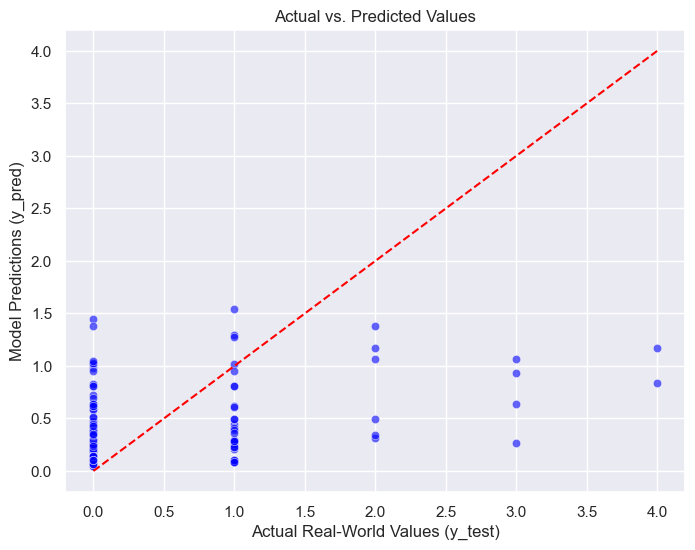

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

# Make the canvas look modern and set its size
sns.set_theme(style="darkgrid")
plt.figure(figsize=(8, 6))

# Create the scatter plot using Seaborn
sns.scatterplot(x=y_test, y=y_pred, alpha=0.6, color="blue")

# Draw the perfect prediction diagonal line (using Matplotlib)
# We draw a red dashed line from the minimum value to the maximum value
min_val = min(min(y_test), min(y_pred))
max_val = max(max(y_test), max(y_pred))
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--')

plt.title("Actual vs. Predicted Values")
plt.xlabel("Actual Real-World Values (y_test)")
plt.ylabel("Model Predictions (y_pred)")
plt.show()

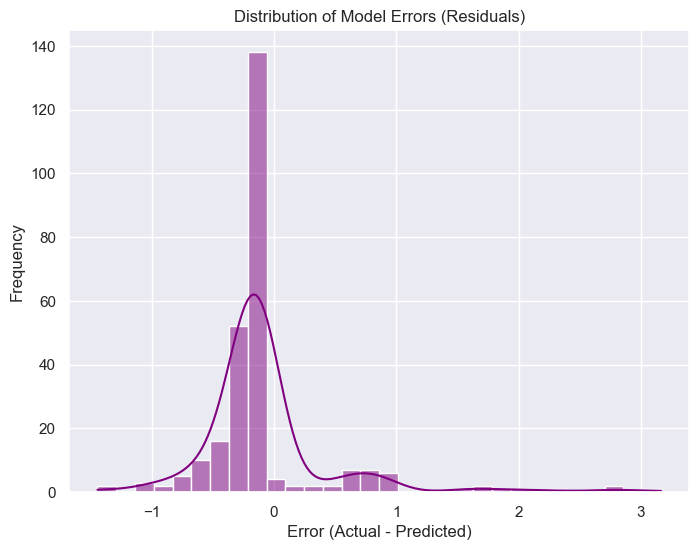

In [10]:
# Calculate the errors
residuals = y_test - y_pred

plt.figure(figsize=(8, 6))

# Create a Seaborn histogram with a smooth density curve (kde)
sns.histplot(residuals, kde=True, color="purple", bins=30)

plt.title("Distribution of Model Errors (Residuals)")
plt.xlabel("Error (Actual - Predicted)")
plt.ylabel("Frequency")
plt.show()